# Build the data for a chest X-ray report assistant
**RSNA 2026 · Lab 08 · Main notebook · 45-minute guided pathway · CPU only**

**The problem:** we want to train a vision-language model (VLM) to draft the **findings** of a chest X-ray report.
It receives an image plus the patient's age, recorded gender and reason for the visit. It should **not** generate an impression.

Today we prepare its training examples. We do not train the model yet.

| Model input | Training target |
|---|---|
| Chest X-ray + age at examination + administrative gender + visit reason | Findings text only |

We will walk through **one patient**, inspect each response, then repeat for a few cases.
No GPU, model download or offline ZIP is needed.

*Dataset note: patient identities, clinical context and reports are invented for this exercise; image sources are attributed.
The small label-derived reports demonstrate a data workflow, not clinical model quality.*

## How to use this notebook in the room
**Proposed faculty handoffs — Wednesday, December 2, 2026, 9:30–10:30 AM Central.**
Use one notebook and one running kernel for the entire live lesson; changing presenters does not require switching notebooks.

| Time (Central) | Lead | Content |
| --- | --- | --- |
| 9:30–9:35 | Felipe | Introduction and lab overview |
| 9:35–9:50 | Eduardo | Sections 1–6: FHIR, authentication, patient/study selection, order and encounter context |
| 9:50–10:05 | Imon | Sections 7–9: report–study matching, findings curation and QIDO/WADO retrieval |
| 10:05–10:20 | Alessia | Sections 10–12: image preprocessing, visual inspection, training pair and cohort exercise if time permits |
| 10:20–10:30 | Felipe | Wrap-up, questions, troubleshooting and catch-up |

Open Colab and start setup during the introduction. Setup delays reduce teaching time; skip section 12
if needed to preserve questions and catch-up. Run collapsed helpers once; expand them only to discuss the code.
The cohort exercise has a completed solution immediately after its exercise cell.

Two embedded recovery points let participants rejoin the single-case walkthrough without downloading a file.
They do not replace the live sourcing steps or cohort exercise.

The [complementary notebook](02_complementary.ipynb) is optional post-session practice, including Arena.
The separate report-matching exercise proposed in RSNA PR #11 is being coordinated with sections 7–9;
its code has not yet been integrated into this notebook.

**Preparation status (November 16, 2026):** the rehearsal hospital was taken offline after testing.
Live FHIR/DICOMweb cells require the instructor to bring it online and supply a classroom token.
The embedded recovery points support only the single-case report/image-processing demonstration.
Fresh Google Colab validation remains pending. No participant credentials are included.


## 1. What is a FHIR connection?
FHIR (pronounced “fire”) is a standard way to exchange healthcare records. A **resource** is one record:
`Patient` stores demographics, `Encounter` stores a visit, and `DiagnosticReport` stores a report.

An **API** lets Python ask a server for information. An **endpoint** or **route** is its address.
Here, connecting just means sending an HTTP request to a known base URL. No database connection is needed.

```text
GET  https://hospital.example/fhir/R4/Patient?name=John
│    └──────── base URL ──────┘└── route ───┘└ filter ┘
└ read information
```

The response is **JSON**: named fields and values, which Python reads as dictionaries and lists.
A search returns a **Bundle**, a container with matching records. Reading `/Patient/pat-001` returns one record.

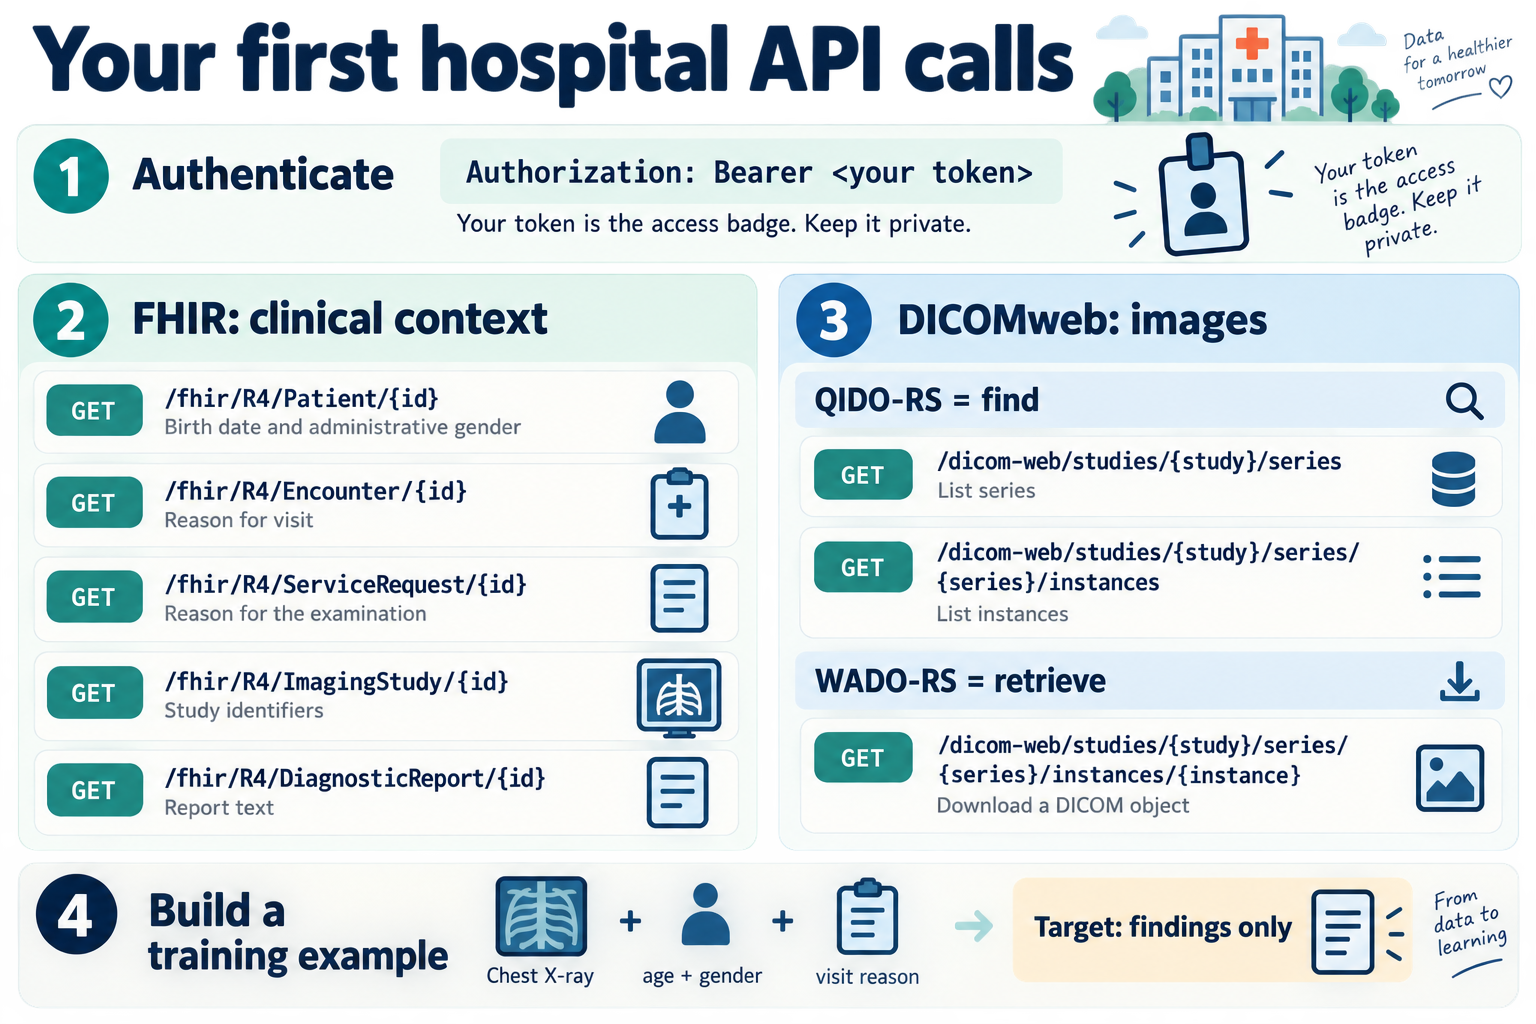

This route menu is a reading guide. The executable cells below are our “Try it out” buttons.

## 2. Install four small libraries
Run each cell from top to bottom with the ▶ button. `httpx` makes requests; `pydicom` opens DICOM files;
NumPy handles pixels; Pillow resizes images.

In [ ]:
import os
import subprocess
import sys
if os.environ.get("RSNA_SKIP_INSTALL") != "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                          "httpx==0.28.1", "pydicom==3.0.1", "numpy==2.2.5", "pillow==11.2.1"])

import base64
import getpass
import io
import json
import re
from pathlib import Path
import httpx
import pydicom
from IPython.display import display

## 3. What is authentication?
The token is your classroom access badge. We send it in an HTTP **header**, not in the URL.
**Bearer** means the server accepts whoever presents that token. Keep it private.
Authentication checks the credential; authorization determines what it can access. Our token permits reading.

Enter the instructor's hospital URL and the token on your card. The password prompt hides the token.
Production hospitals often use OAuth/SMART login; we start with an already-issued token.

**During preparation:** the event URL is not deployed yet. Run this notebook locally with
`http://localhost:8000`. A cloud Colab runtime cannot reach your laptop's localhost.

In [ ]:
BASE_URL = os.environ.get("RSNA_BASE_URL", "https://rsnalearninglab.eduardofarina.com").rstrip("/")
TOKEN = os.environ.get("RSNA_TOKEN") or getpass.getpass("Classroom token: ")
client = httpx.Client(headers={"Authorization": f"Bearer {TOKEN}"}, timeout=120)

response = client.get(BASE_URL + "/fhir/R4/metadata")
print("HTTP status:", response.status_code)
response.raise_for_status()
print("FHIR version:", response.json()["fhirVersion"])

**200** means success. **401** means a missing, invalid, expired or revoked token.
**404** means the route or record was not found. **429** means slow down and retry later.
If connection fails, check that the hospital is running and the URL is reachable from your notebook.

From now on, this small helper repeats the request/error check. It also keeps the token on our hospital's origin.

In [ ]:
from urllib.parse import urljoin, urlparse

def get(path, **kwargs):
    url = urljoin(BASE_URL + "/", path)
    if urlparse(url)[:2] != urlparse(BASE_URL)[:2]:
        raise ValueError("Unexpected server address")
    response = client.get(url, **kwargs)
    response.raise_for_status()
    return response

## 4. Find a patient — your first search
`?name=John` is a search filter. Inspect the small part of the returned Bundle below.
The FHIR `id` is an API identifier; it is different from the hospital medical record number (MRN).

In [ ]:
bundle = get("/fhir/R4/Patient", params={"name": "John"}).json()
print("Matches:", bundle["total"])
patient = bundle["entry"][0]["resource"]
print(json.dumps({key: patient[key] for key in ["id", "name", "birthDate", "gender"]}, indent=2))
patient_id = patient["id"]

## 5. Which examination do we want?
Search `ImagingStudy` for this patient and modality `CR` (computed radiography).
`DX` is another radiograph modality; CT and MR are outside today's cohort.

We will use only **one page** in these first examples. The optional cohort step later follows all pages.
Choose a study ID from the displayed list.

In [ ]:
bundle = get("/fhir/R4/ImagingStudy", params={"patient": patient_id, "modality": "CR"}).json()
studies = [entry["resource"] for entry in bundle.get("entry", [])]
assert studies, "No CR studies found for this patient"
print([(study["id"], study["started"]) for study in studies])
study = studies[0]  # Change the index to explore another examination.

## 6. Follow the links: order → visit → patient context
A FHIR **reference** is a link such as `ServiceRequest/order-001`. Follow it to read that exact record.
`ServiceRequest.reasonCode` is the examination indication; `Encounter.reasonCode` is the visit reason.
They happen to match in our examples but can differ in a real hospital.

Age must be calculated **on the examination date**, not today. `Patient.gender` is administrative gender;
it is not a measurement of biological sex. Missing or unknown values remain unknown.

In [ ]:
order = get("/fhir/R4/" + study["basedOn"][0]["reference"]).json()
encounter = get("/fhir/R4/" + order["encounter"]["reference"]).json()
assert order["subject"] == encounter["subject"] == study["subject"]
print("Visit reason:", encounter["reasonCode"][0]["text"])
print("Exam indication:", order["reasonCode"][0]["text"])

In [ ]:
def age_at_study(birth_date, study_date):
    """Calculate completed years at acquisition, retaining missing/partial dates."""
    from datetime import date

    if not birth_date or len(birth_date) != 10:
        return None
    birth = date.fromisoformat(birth_date)
    acquired = date.fromisoformat(study_date[:10])
    if acquired < birth:
        raise ValueError("Study date precedes birth date")
    return acquired.year - birth.year - ((acquired.month, acquired.day) < (birth.month, birth.day))

context = {
    "age_years": age_at_study(patient.get("birthDate"), study["started"]),
    "administrative_gender": patient.get("gender", "unknown"),
    "reason_for_visit": encounter["reasonCode"][0]["text"],
}
print(context)

## 7. Find the report for this exact examination
A patient can have several examinations. Matching by patient alone is not enough.
We require the report's `imagingStudy` and `basedOn` links to match our study and order.
Then we use the latest finalized, amended or corrected report; preliminary reports are excluded.

In [ ]:
bundle = get("/fhir/R4/DiagnosticReport", params={"patient": patient_id, "_count": 100}).json()
reports = [entry["resource"] for entry in bundle.get("entry", [])]
matching = [r for r in reports
            if r["status"] in ("final", "amended", "corrected")
            and {"reference": "ImagingStudy/" + study["id"]} in r.get("imagingStudy", [])
            and {"reference": "ServiceRequest/" + order["id"]} in r.get("basedOn", [])]
assert matching, "No finalized report for this examination; skip this case"
report = max(matching, key=lambda r: r["issued"])
assert report["subject"] == study["subject"]
# Base64 is an encoding used to carry file content inside JSON, not encryption.
report_text = base64.b64decode(report["presentedForm"][0]["data"]).decode("utf-8")
print(report_text)

### Recovery point 1 — rejoin at report processing
Only use this if you lost track during the FHIR steps, or the hospital is unavailable.
Run section 2 (imports) first. Then run the helper below, set the switch to
`True`, and continue at section 8. The original API calls remain above for you to revisit.
This restores the prepared patient, study, order, visit, context and report for **study-001**.

In [ ]:
#@title Recovery helper: one embedded teaching case (run once)
import gzip
_RECOVERY_PAYLOAD = '...'
def recovery_case():
    return json.loads(gzip.decompress(base64.b64decode(_RECOVERY_PAYLOAD)))


In [ ]:
USE_FHIR_RECOVERY = False
if USE_FHIR_RECOVERY:
    saved = recovery_case()
    patient, study, order, encounter, report = [saved[key] for key in ["patient", "study", "order", "encounter", "report"]]
    patient_id = patient["id"]
    context = saved["context"]
    report_text = base64.b64decode(report["presentedForm"][0]["data"]).decode()
    print("Restored study-001. Continue at section 8.")

## 8. Keep findings; remove the impression
Our **target** is only the findings section. We remove the report header, patient identifiers and impression
by selecting text **between section headings**. We do not remove words such as “no” or “possible”.

This simple rule is appropriate for our known report template. Unlabeled reports need review.
No language model is needed for this transformation. The impression and report text must never be part of the model input.

In [ ]:
def findings_only(text):
    """Extract the labeled findings section; reject unlabeled reports for review."""
    match = re.search(
        r"(?ims)^\s*findings(?:\s*\(preliminary\))?\s*:\s*(.*?)"
        r"(?=^\s*(?:impression|conclusion|recommendations|addendum)\s*:|\Z)",
        text,
    )
    if not match or not match.group(1).strip():
        raise ValueError("No labeled findings section; review this report manually")
    return " ".join(match.group(1).split())

target = findings_only(report_text)
print("Model target:", target)

## 9. From FHIR to DICOMweb
FHIR gives us clinical context and imaging identifiers. **DICOMweb** lets us query and retrieve images from the PACS.
A study contains series; a series contains instances (DICOM objects).

| Call | Purpose | Response |
|---|---|---|
| QIDO-RS: `GET /dicom-web/studies/{study}/series` | Find series | DICOM JSON |
| QIDO-RS: `GET /dicom-web/studies/{study}/series/{series}/instances` | Find instances | DICOM JSON |
| WADO-RS: same path + `/{instance}` | Retrieve one object | DICOM bytes inside a multipart response |

FHIR resource IDs and DICOM UIDs are different. First read the Study Instance UID from FHIR.
DICOM JSON uses tag numbers: `0020000E` = Series Instance UID; `00080018` = SOP Instance UID.

In [ ]:
study_uid = next(item["value"].removeprefix("urn:oid:") for item in study["identifier"]
                 if item["system"] == "urn:dicom:uid")
series_path = f"/dicom-web/studies/{study_uid}/series"
series_list = get(series_path, headers={"Accept": "application/dicom+json"}).json()
print("Series found:", len(series_list))
series_uid = series_list[0]["0020000E"]["Value"][0]
instances_path = f"{series_path}/{series_uid}/instances"
instances = get(instances_path, headers={"Accept": "application/dicom+json"}).json()
instance_uid = instances[0]["00080018"]["Value"][0]
print("Instances in this series:", len(instances))

Our curated CXR cases have one series and one image. Selecting the first item is specific to this pack;
a general dataset needs explicit view, series and frame selection.

The server wraps the DICOM file in a **multipart envelope**, like an attachment to a message.
Run the supplied helper to open that envelope; its details are not the focus of the lesson.

In [ ]:
#@title Helper: open the DICOM response envelope (run once)
from email.parser import BytesParser
from email.policy import default

def read_dicom(response):
    content_type = response.headers.get("content-type", "")
    if content_type.startswith("multipart/"):
        envelope = BytesParser(policy=default).parsebytes(
            ("Content-Type: " + content_type + "\r\nMIME-Version: 1.0\r\n\r\n").encode()
            + response.content)
        parts = [p.get_payload(decode=True) for p in envelope.iter_parts()
                 if p.get_content_type() == "application/dicom"]
        if len(parts) != 1:
            raise ValueError("Expected one DICOM attachment")
        data = parts[0]
    else:
        data = response.content
    return pydicom.dcmread(io.BytesIO(data))

In [ ]:
response = get(f"{instances_path}/{instance_uid}",
               headers={"Accept": 'multipart/related; type="application/dicom"; transfer-syntax=*'})
ds = read_dicom(response)
assert str(ds.StudyInstanceUID) == study_uid
assert str(ds.SeriesInstanceUID) == series_uid
assert str(ds.SOPInstanceUID) == instance_uid
print("Pixel array:", ds.pixel_array.shape)
print("Photometric interpretation:", ds.PhotometricInterpretation)
print("Window center / width:", ds.get("WindowCenter", "not supplied"), ds.get("WindowWidth", "not supplied"))

### Recovery point 2 — rejoin at image processing
If DICOMweb retrieval failed, run the recovery helper above and set this switch to `True`.
It opens the embedded DICOM for **study-001**. Use recovery point 1 as well if your current case differs;
the assertion prevents pairing this image with another patient's report. Continue at section 10.
You can skip the network cells in section 9 when using this recovery point.

In [ ]:
USE_DICOM_RECOVERY = False
if USE_DICOM_RECOVERY:
    saved = recovery_case()
    assert study["id"] == saved["study"]["id"], "Use recovery point 1 first to restore the matching case"
    ds = pydicom.dcmread(io.BytesIO(base64.b64decode(saved["dicom_base64"])))
    study_uid = str(ds.StudyInstanceUID)
    print("Prepared DICOM loaded. Continue at section 10.")

## 10. Turn DICOM pixels into a model-ready image
A DICOM file contains metadata and pixels. Its pixel values are not always display-ready.

1. Decode the pixels and apply the modality LUT/rescale, if present.
2. Apply the stored VOI LUT/window. Without one, use a percentile contrast range for this demonstration.
3. Handle `MONOCHROME1` inversion and set padding pixels to black.
4. Convert to 8-bit grayscale and resize the **longest side to at most 896 pixels**, without upscaling.

**Windowing** maps a chosen intensity range to black–white. A narrower range increases contrast but clips more values.
Use the radiograph's own settings; do not apply a CT lung window to a chest radiograph.

**896 is a teaching budget, not a universal VLM limit.** Resizing preserves aspect ratio (with integer rounding),
but reduces detail. A 2048 × 1536 image becomes 896 × 672. The chosen model's processor may resize or crop again.
The supplied helper keeps the longer DICOM handling out of our first API examples.

In [ ]:
#@title Helper: prepare a grayscale radiograph (run once; expand to inspect)
def prepare_cxr(ds, max_side=896, window=None):
    """Single-frame grayscale teaching pipeline; window=(center,width) is optional."""
    import numpy as np
    from PIL import Image
    from pydicom.pixels import apply_modality_lut, apply_voi_lut

    if max_side < 1:
        raise ValueError("max_side must be positive")
    raw = ds.pixel_array
    if raw.ndim != 2 or ds.PhotometricInterpretation not in ("MONOCHROME1", "MONOCHROME2"):
        raise ValueError("This exercise expects a single-frame grayscale radiograph")
    valid = np.isfinite(raw)
    if "PixelPaddingValue" in ds:
        low = float(ds.PixelPaddingValue)
        high = float(ds.get("PixelPaddingRangeLimit", low))
        valid &= (raw < min(low, high)) | (raw > max(low, high))
    pixels = apply_modality_lut(raw, ds).astype(float)
    valid &= np.isfinite(pixels)
    if not valid.any():
        raise ValueError("No usable pixels")
    if window is not None:
        center, width = window
        if not np.isfinite([center, width]).all() or width <= 0:
            raise ValueError("Window width must be positive and values finite")
        # Explicit linear teaching window, distinct from DICOM's LINEAR formula.
        low, high = center - width / 2, center + width / 2
        method = "manual linear window"
    elif "VOILUTSequence" in ds or ("WindowCenter" in ds and "WindowWidth" in ds):
        pixels = apply_voi_lut(pixels, ds).astype(float)
        if "VOILUTSequence" in ds:
            low, high = 0, 2 ** int(ds.VOILUTSequence[0].LUTDescriptor[2]) - 1
        else:
            # pydicom windowing output spans the modality-transformed bit range.
            bits = int(ds.BitsStored)
            low, high = (
                (0, 2**bits - 1) if ds.PixelRepresentation == 0 else (-(2 ** (bits - 1)), 2 ** (bits - 1) - 1)
            )
            if "ModalityLUTSequence" in ds:
                low, high = 0, 2 ** int(ds.ModalityLUTSequence[0].LUTDescriptor[2]) - 1
            else:
                slope, intercept = float(ds.get("RescaleSlope", 1)), float(ds.get("RescaleIntercept", 0))
                low, high = sorted((low * slope + intercept, high * slope + intercept))
        method = "DICOM VOI LUT/window (first preset)"
    else:
        low, high = np.percentile(pixels[valid], [0.5, 99.5])
        method = "0.5–99.5 percentile fallback"
    pixels = np.clip((pixels - low) / max(float(high - low), 1e-8), 0, 1)
    if ds.PhotometricInterpretation == "MONOCHROME1":
        pixels = 1 - pixels
    pixels[~valid] = 0
    image = Image.fromarray(np.rint(pixels * 255).astype("uint8"))
    original_size = image.size
    image.thumbnail((max_side, max_side), Image.Resampling.LANCZOS)
    return image, {
        "original_size": original_size,
        "output_size": image.size,
        "intensity_method": method,
        "max_side": max_side,
    }

In [ ]:
MAX_SIDE = 896
image, preprocessing = prepare_cxr(ds, max_side=MAX_SIDE)
print(preprocessing)
display(image)

## 11. Assemble one training example
Only the image and clinical context go into the prompt. Findings are the separate supervised answer.
We keep IDs for tracing and patient-level splitting, but exclude them from the prompt.

In [ ]:
def make_prompt(context):
    age = context["age_years"] if context["age_years"] is not None else "unknown"
    return ("Draft the findings section of this chest X-ray report. Do not include an impression.\n"
            f"Age at examination: {age} years.\n"
            f"Administrative gender: {context['administrative_gender']}.\n"
            f"Reason for visit: {context['reason_for_visit']}.")

output_dir = Path("cxr-training")
output_dir.mkdir(exist_ok=True)
image_path = output_dir / f"{study['id']}.png"
image.save(image_path)
record = {"patient_id": patient_id, "study_id": study["id"], "report_id": report["id"],
          "image_path": str(image_path), "context": context,
          "prompt": make_prompt(context), "target": target, "preprocessing": preprocessing}
Path("image-report-pair.json").write_text(json.dumps(record, indent=2))
print("INPUT:\n" + record["prompt"])
print("\nTARGET:\n" + record["target"])

## 12. One short exercise: repeat the same workflow
The helper below repeats the calls you already learned and follows every search page.
Predict what happens for **study-002** (preliminary and corrected reports) and **study-004** (no report).
Then run the completed solution immediately after the exercise cell. No extra exercise is required.
If time is short, follow the presenter through the solution.

In [ ]:
#@title Helper: repeat the same workflow for selected studies

def search_all(resource, **params):
    page = get("/fhir/R4/" + resource, params=params).json()
    records = []
    while True:
        records.extend(entry["resource"] for entry in page.get("entry", []))
        next_url = next((link["url"] for link in page.get("link", []) if link["relation"] == "next"), None)
        if not next_url:
            return records
        page = get(next_url).json()


def build_case(study_id):
    study = get("/fhir/R4/ImagingStudy/" + study_id).json()
    if not any(m["code"] in ("CR", "DX") for m in study["modality"]):
        raise ValueError("Not a chest radiograph case in this pack")
    patient = get("/fhir/R4/" + study["subject"]["reference"]).json()
    order_ref = study["basedOn"][0]["reference"]
    order = get("/fhir/R4/" + order_ref).json()
    encounter = get("/fhir/R4/" + order["encounter"]["reference"]).json()
    assert order["subject"] == encounter["subject"] == study["subject"]
    reports = search_all("DiagnosticReport", patient=patient["id"])
    reports = [r for r in reports if r["status"] in ("final", "corrected", "amended")
               and {"reference": "ImagingStudy/" + study_id} in r.get("imagingStudy", [])
               and {"reference": order_ref} in r.get("basedOn", [])
               and r["subject"] == study["subject"]]
    if not reports:
        raise ValueError("No finalized report")
    report = max(reports, key=lambda r: r["issued"])
    target = findings_only(base64.b64decode(report["presentedForm"][0]["data"]).decode())
    context = {"age_years": age_at_study(patient.get("birthDate"), study["started"]),
               "administrative_gender": patient.get("gender", "unknown"),
               "reason_for_visit": next((r["text"] for r in encounter.get("reasonCode", []) if r.get("text")), "unknown")}
    uid = next(i["value"].removeprefix("urn:oid:") for i in study["identifier"] if i["system"] == "urn:dicom:uid")
    series = get(f"/dicom-web/studies/{uid}/series", headers={"Accept": "application/dicom+json"}).json()
    assert len(series) == 1, "Review series selection"
    series_uid = series[0]["0020000E"]["Value"][0]
    path = f"/dicom-web/studies/{uid}/series/{series_uid}/instances"
    instances = get(path, headers={"Accept": "application/dicom+json"}).json()
    assert len(instances) == 1, "Review instance selection"
    instance_uid = instances[0]["00080018"]["Value"][0]
    ds = read_dicom(get(path + "/" + instance_uid, headers={"Accept": 'multipart/related; type="application/dicom"; transfer-syntax=*'}))
    assert str(ds.StudyInstanceUID) == uid and str(ds.SeriesInstanceUID) == series_uid
    assert str(ds.SOPInstanceUID) == instance_uid
    image, preprocessing = prepare_cxr(ds, max_side=MAX_SIDE)
    path = output_dir / f"{study_id}.png"
    image.save(path)
    return {"patient_id": patient["id"], "study_id": study_id, "report_id": report["id"],
            "image_path": str(path), "context": context, "prompt": make_prompt(context),
            "target": target, "preprocessing": preprocessing}

In [ ]:
# Exercise: predict the outcome before running the completed solution below.
# Which report should be used for study-002? What should happen to study-004?
# Optional: change the selected IDs in the solution to explore another case.

**Completed solution — run this cell to continue.**

In [ ]:
SELECTED_STUDIES = ["study-001", "study-002", "study-003", "study-004"]
records, skipped = [], []
for study_id in SELECTED_STUDIES:
    try:
        records.append(build_case(study_id))
    except ValueError as error:
        skipped.append({"study_id": study_id, "reason": str(error)})
Path("cxr-training.jsonl").write_text("".join(json.dumps(row) + "\n" for row in records))
print("Training examples:", len(records))
print("Skipped:", skipped)

## Finish: inspect your complete example
You now have an image, clinical context and a separate findings-only target. These are the core outcome.
The corrected report is selected; the missing-report case is skipped. Duplicate detection and dataset splits
are in the complementary notebook, alongside the loader and deployment example.

Stop here for questions. No GPU or Arena call is needed to complete this lab.

In [ ]:
client.close()